In [ ]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime

import sys
sys.path.insert(0, 'smoothing')
import common

In [30]:
# ------------------------------------------------------------
# 0) Load processed logs (telemetry timestamp already applied)
# ------------------------------------------------------------
PROCESSED_JSON_PATH = "2025-12-19_10-50-09/pg2gw/processed_logs.json"

with open(PROCESSED_JSON_PATH, "r", encoding="utf-8") as f:
    events = json.load(f)

print(f"Total events loaded: {len(events)}")
print("\nSample event:")
print(json.dumps(events[0], indent=2))

Total events loaded: 1851

Sample event:
{
  "timestamp": "2025-12-18T14:45:20Z",
  "device_id": "6000000-2000-000003-2550",
  "type": "filtered_confidence",
  "pixel_x": null,
  "pixel_y": null,
  "cm_x": null,
  "cm_y": null,
  "confidence": 0.394749,
  "box": {
    "x": 179,
    "y": 0,
    "w": 140,
    "h": 148
  }
}


In [31]:
# ------------------------------------------------------------
# 1) Filter by EXPERIMENT time window: 10:00–10:49 (UTC)
#    END IS EXCLUSIVE (important!)
# ------------------------------------------------------------
START_TIME = datetime.strptime("10:00", "%H:%M").time()
END_TIME   = datetime.strptime("10:49", "%H:%M").time()

filtered = []
for e in events:
    ts = pd.to_datetime(e["timestamp"], utc=True)
    if START_TIME <= ts.time() < END_TIME:
        filtered.append(e)

print(f"\nEvents in 10:00–10:49: {len(filtered)}")


Events in 10:00–10:49: 275


In [32]:
# ------------------------------------------------------------
# 2) Convert to DataFrame
# ------------------------------------------------------------
df = pd.DataFrame(filtered)
df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)

print("\nEvent types:")
print(df["type"].value_counts())




Event types:
type
filtered_confidence    121
detection              117
filtered_novelty        37
Name: count, dtype: int64


In [33]:
# ------------------------------------------------------------
# 3) CORRECT aggregation:
#    one telemetry message = (timestamp, device_id)
# ------------------------------------------------------------
ts_msgs = (
    df.groupby(["timestamp", "device_id", "type"])
      .size()
      .unstack(fill_value=0)
      .reset_index()
      .sort_values(["timestamp", "device_id"])
      .reset_index(drop=True)
)

# Ensure all columns exist
for col in ["detection", "filtered_confidence", "filtered_novelty"]:
    if col not in ts_msgs.columns:
        ts_msgs[col] = 0

ts_msgs["all"] = (
    ts_msgs["detection"]
    + ts_msgs["filtered_confidence"]
    + ts_msgs["filtered_novelty"]
)

print("\nPer-telemetry-message table (first rows):")
display(ts_msgs.head(10))



Per-telemetry-message table (first rows):


type,timestamp,device_id,detection,filtered_confidence,filtered_novelty,all
0,2025-12-19 10:00:00+00:00,6000000-2000-000003-2550,0,1,0,1
1,2025-12-19 10:00:11+00:00,6000000-2000-000003-2550,0,1,0,1
2,2025-12-19 10:00:22+00:00,6000000-2000-000003-2550,0,0,1,1
3,2025-12-19 10:00:33+00:00,6000000-2000-000003-2550,0,1,0,1
4,2025-12-19 10:00:44+00:00,6000000-2000-000003-2550,0,1,0,1
5,2025-12-19 10:00:55+00:00,6000000-2000-000003-2550,0,0,1,1
6,2025-12-19 10:01:06+00:00,6000000-2000-000003-2550,0,0,1,1
7,2025-12-19 10:01:17+00:00,6000000-2000-000003-2550,0,0,1,1
8,2025-12-19 10:01:27+00:00,6000000-2000-000003-2550,0,0,1,1
9,2025-12-19 10:01:38+00:00,6000000-2000-000003-2550,0,0,1,1


In [34]:
# ------------------------------------------------------------
# 4) GLOBAL statistics (THIS is the answer you care about)
# ------------------------------------------------------------
MAX_PER_MESSAGE = int(ts_msgs["all"].max())

print("\n============================================================")
print("FULL EXPERIMENT (10:00–10:49) STATISTICS")
print("============================================================")
print(f"Total telemetry messages: {len(ts_msgs)}")
print(f"MAX detections in ONE telemetry message: {MAX_PER_MESSAGE}")
print(f"Average detections per message: {ts_msgs['all'].mean():.2f}")

print("\nDistribution (#detections -> #messages):")
print(ts_msgs["all"].value_counts().sort_index())


FULL EXPERIMENT (10:00–10:49) STATISTICS
Total telemetry messages: 223
MAX detections in ONE telemetry message: 3
Average detections per message: 1.23

Distribution (#detections -> #messages):
all
1    183
2     28
3     12
Name: count, dtype: int64


In [35]:
# ------------------------------------------------------------
# 5) Show messages that hit MAX (with breakdown)
# ------------------------------------------------------------
max_rows = ts_msgs[ts_msgs["all"] == MAX_PER_MESSAGE]

print("\nTelemetry messages with MAX detections:")
display(
    max_rows[
        ["timestamp", "device_id",
         "detection", "filtered_confidence", "filtered_novelty", "all"]
    ]
)

print("\nType breakdown for MAX messages:")
for _, r in max_rows.iterrows():
    sub = df[
        (df["timestamp"] == r["timestamp"]) &
        (df["device_id"] == r["device_id"])
    ]
    print(f"\n--- {r['timestamp'].isoformat()} | device={r['device_id']} ---")
    print(sub["type"].value_counts())
    display(sub)



Telemetry messages with MAX detections:


type,timestamp,device_id,detection,filtered_confidence,filtered_novelty,all
136,2025-12-19 10:31:25+00:00,6000000-2000-000003-2550,1,2,0,3
137,2025-12-19 10:31:36+00:00,6000000-2000-000003-2550,1,2,0,3
138,2025-12-19 10:31:47+00:00,6000000-2000-000003-2550,2,1,0,3
139,2025-12-19 10:31:58+00:00,6000000-2000-000003-2550,1,2,0,3
141,2025-12-19 10:32:20+00:00,6000000-2000-000003-2550,0,3,0,3
151,2025-12-19 10:34:11+00:00,6000000-2000-000003-2550,2,1,0,3
153,2025-12-19 10:34:33+00:00,6000000-2000-000003-2550,1,2,0,3
154,2025-12-19 10:34:44+00:00,6000000-2000-000003-2550,2,1,0,3
156,2025-12-19 10:35:06+00:00,6000000-2000-000003-2550,2,1,0,3
157,2025-12-19 10:35:17+00:00,6000000-2000-000003-2550,2,1,0,3



Type breakdown for MAX messages:

--- 2025-12-19T10:31:25+00:00 | device=6000000-2000-000003-2550 ---
type
filtered_confidence    2
detection              1
Name: count, dtype: int64


,timestamp,device_id,type,pixel_x,pixel_y,cm_x,cm_y,confidence,box,gmm_label
145,2025-12-19 10:31:25+00:00,6000000-2000-000003-2550,detection,76.0,79.0,-169.0,92.0,0.605251,"{'x': 42, 'y': 63, 'w': 82, 'h': 69}",NaN
146,2025-12-19 10:31:25+00:00,6000000-2000-000003-2550,filtered_confidence,NaN,NaN,NaN,NaN,0.298430,"{'x': 100, 'y': 121, 'w': 50, 'h': 96}",NaN
147,2025-12-19 10:31:25+00:00,6000000-2000-000003-2550,filtered_confidence,NaN,NaN,NaN,NaN,0.217180,"{'x': 111, 'y': 35, 'w': 59, 'h': 81}",NaN



--- 2025-12-19T10:31:36+00:00 | device=6000000-2000-000003-2550 ---
type
filtered_confidence    2
detection              1
Name: count, dtype: int64


...

,timestamp,device_id,type,pixel_x,pixel_y,cm_x,cm_y,confidence,box,gmm_label
195,2025-12-19 10:35:17+00:00,6000000-2000-000003-2550,detection,128.0,158.0,-57.0,-58.0,0.701570,"{'x': 101, 'y': 138, 'w': 53, 'h': 78}",NaN
196,2025-12-19 10:35:17+00:00,6000000-2000-000003-2550,detection,76.0,84.0,-168.0,81.0,0.500000,"{'x': 40, 'y': 66, 'w': 80, 'h': 70}",NaN
197,2025-12-19 10:35:17+00:00,6000000-2000-000003-2550,filtered_confidence,NaN,NaN,NaN,NaN,0.394749,"{'x': 120, 'y': 42, 'w': 52, 'h': 76}",NaN



--- 2025-12-19T10:35:29+00:00 | device=6000000-2000-000003-2550 ---
type
filtered_confidence    2
detection              1
Name: count, dtype: int64


,timestamp,device_id,type,pixel_x,pixel_y,cm_x,cm_y,confidence,box,gmm_label
198,2025-12-19 10:35:29+00:00,6000000-2000-000003-2550,detection,124.0,158.0,-65.0,-59.0,0.605251,"{'x': 100, 'y': 138, 'w': 54, 'h': 78}",NaN
199,2025-12-19 10:35:29+00:00,6000000-2000-000003-2550,filtered_confidence,NaN,NaN,NaN,NaN,0.394749,"{'x': 40, 'y': 65, 'w': 91, 'h': 69}",NaN
200,2025-12-19 10:35:29+00:00,6000000-2000-000003-2550,filtered_confidence,NaN,NaN,NaN,NaN,0.217180,"{'x': 119, 'y': 41, 'w': 53, 'h': 79}",NaN



--- 2025-12-19T10:35:40+00:00 | device=6000000-2000-000003-2550 ---
type
filtered_confidence    2
detection              1
Name: count, dtype: int64


,timestamp,device_id,type,pixel_x,pixel_y,cm_x,cm_y,confidence,box,gmm_label
201,2025-12-19 10:35:40+00:00,6000000-2000-000003-2550,detection,80.0,87.0,-157.0,74.0,0.500000,"{'x': 40, 'y': 66, 'w': 91, 'h': 68}",NaN
202,2025-12-19 10:35:40+00:00,6000000-2000-000003-2550,filtered_confidence,NaN,NaN,NaN,NaN,0.394749,"{'x': 120, 'y': 43, 'w': 54, 'h': 75}",NaN
203,2025-12-19 10:35:40+00:00,6000000-2000-000003-2550,filtered_confidence,NaN,NaN,NaN,NaN,0.394749,"{'x': 101, 'y': 111, 'w': 53, 'h': 104}",NaN


In [ ]:
# ------------------------------------------------------------
# 6) Plot + vertical split lines (using timestamps from common.py)
# ------------------------------------------------------------
plt.figure(figsize=(16, 6))

x = np.arange(len(ts_msgs))
labels = ts_msgs["timestamp"].dt.strftime("%H:%M:%S").tolist()

plt.plot(x, ts_msgs["all"], ".-", label="All detections / message")
plt.plot(x, ts_msgs["detection"], ".-", label="Accepted / message")
plt.plot(x, ts_msgs["filtered_confidence"], ".-", label="Filtered (confidence) / message")
plt.plot(x, ts_msgs["filtered_novelty"], ".-", label="Filtered (novelty) / message")

# Get the date from the first timestamp
base_date = ts_msgs["timestamp"].iloc[0].date()

# Convert time constants from common.py to full datetimes
splits = [
    (datetime.combine(base_date, common.ONE_PERSON_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "Start single-person", "10:05"),
    (datetime.combine(base_date, common.THREE_PERSONS_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "Start three-person", "10:30"),
    (datetime.combine(base_date, common.ONE_PERSON_CHAIRS_START).replace(tzinfo=ts_msgs["timestamp"].iloc[0].tzinfo), "Start seat-switching (sensor 3)", "10:38"),
]

# Draw vertical lines at split timestamps
ymax = float(ts_msgs[["all", "detection", "filtered_confidence", "filtered_novelty"]].to_numpy().max())
y_text = ymax + 0.1  # small headroom for labels

ts_series = ts_msgs["timestamp"].reset_index(drop=True)
for split_time, label, hhmm in splits:
    # Find the index of the closest timestamp
    diffs = (ts_series - split_time).abs()
    idx = int(diffs.idxmin())
    
    plt.axvline(idx, linestyle="--", linewidth=1)
    # Put text near top
    plt.text(idx + 0.5, y_text, f"{hhmm} {label}", rotation=90, va="bottom", ha="left", fontsize=9)

# x ticks formatting
step = max(1, len(x) // 12)
plt.xticks(
    ticks=np.arange(0, len(x), step),
    labels=[labels[i] for i in range(0, len(x), step)],
    rotation=45,
    ha="right"
)

plt.xlabel("Telemetry message index (timestamp shown)")
plt.ylabel("Detections per message")
plt.title(
    f"Detections per telemetry message (10:00–10:49 UTC)\n"
    f"MAX per message = {int(ts_msgs['all'].max())}"
)
plt.ylim(bottom=-0.05, top=y_text + 0.2)
plt.legend()
plt.grid(alpha=0.4)
plt.tight_layout()
plt.show()

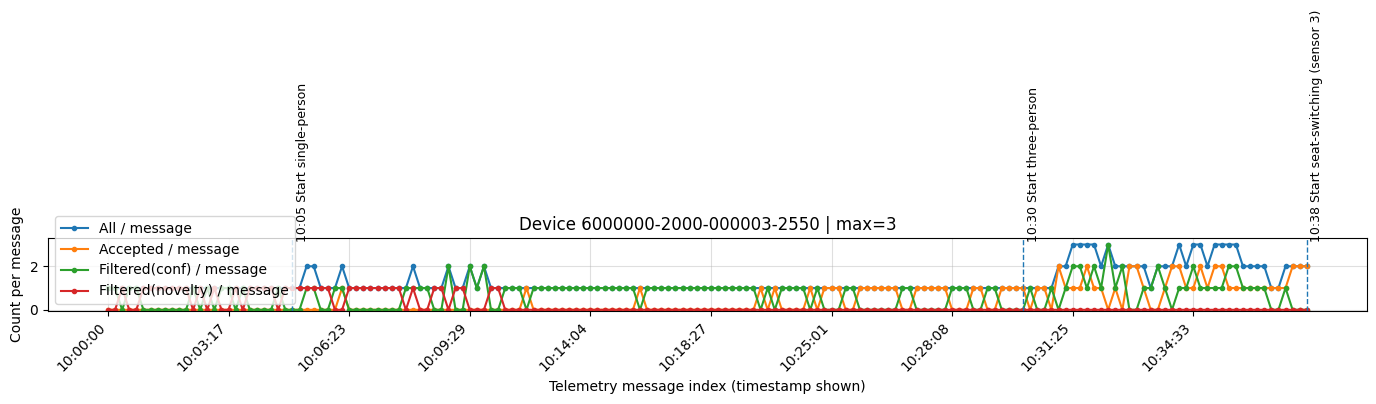


Device 6000000-2000-000003-2550 split alignment:
  10:05 -> idx=26, nearest_ts=10:04:56
  10:30 -> idx=129, nearest_ts=10:29:56
  10:38 -> idx=169, nearest_ts=10:37:30


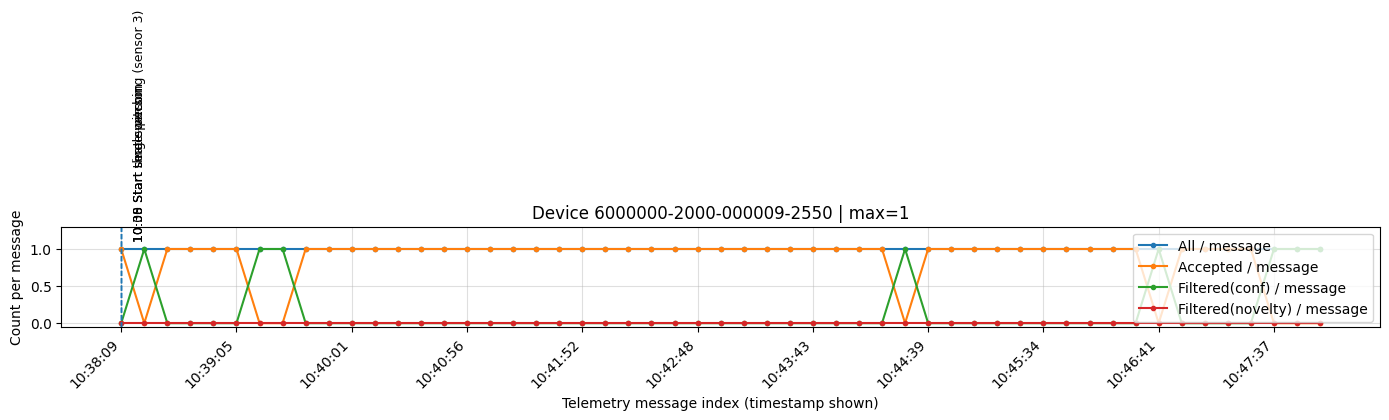


Device 6000000-2000-000009-2550 split alignment:
  10:05 -> idx=0, nearest_ts=10:38:09
  10:30 -> idx=0, nearest_ts=10:38:09
  10:38 -> idx=0, nearest_ts=10:38:09


In [37]:
# ------------------------------------------------------------
# 7) Per-device sanity plots WITH experiment split lines
# ------------------------------------------------------------

def nearest_index_for_hhmm(ts_series: pd.Series, hhmm: str) -> int | None:
    """
    Return index of telemetry message closest to HH:MM boundary.
    If no message exists near that time for this device, return None.
    """
    if ts_series.empty:
        return None

    t = datetime.strptime(hhmm, "%H:%M").time()
    boundary = ts_series.iloc[0].replace(
        hour=t.hour, minute=t.minute, second=0, microsecond=0
    )

    diffs = (ts_series - boundary).abs()
    return int(diffs.idxmin())


# Experiment step boundaries you requested
# (label, HH:MM)
SPLITS = [
    ("Start single-person", "10:05"),
    ("Start three-person", "10:30"),
    ("Start seat-switching (sensor 3)", "10:38"),
]

for dev, sub in ts_msgs.groupby("device_id", sort=False):
    plt.figure(figsize=(14, 4))

    sub = sub.reset_index(drop=True)
    x = np.arange(len(sub))
    labels = sub["timestamp"].dt.strftime("%H:%M:%S").tolist()

    # Lines
    plt.plot(x, sub["all"], ".-", label="All / message")
    plt.plot(x, sub["detection"], ".-", label="Accepted / message")
    plt.plot(x, sub["filtered_confidence"], ".-", label="Filtered(conf) / message")
    plt.plot(x, sub["filtered_novelty"], ".-", label="Filtered(novelty) / message")

    # ---- vertical experiment split lines (per device)
    ts_series = sub["timestamp"]
    ymax = float(
        sub[["all", "detection", "filtered_confidence", "filtered_novelty"]]
        .to_numpy()
        .max()
    )
    y_text = ymax + 0.1

    for label, hhmm in SPLITS:
        idx = nearest_index_for_hhmm(ts_series, hhmm)
        if idx is None:
            continue
        plt.axvline(idx, linestyle="--", linewidth=1)
        plt.text(
            idx + 0.5,
            y_text,
            f"{hhmm} {label}",
            rotation=90,
            va="bottom",
            ha="left",
            fontsize=9,
        )

    # X ticks (timestamps as labels)
    step = max(1, len(x) // 10)
    plt.xticks(
        ticks=np.arange(0, len(x), step),
        labels=[labels[i] for i in range(0, len(x), step)],
        rotation=45,
        ha="right",
    )

    plt.xlabel("Telemetry message index (timestamp shown)")
    plt.ylabel("Count per message")
    plt.title(f"Device {dev} | max={int(sub['all'].max())}")
    plt.legend()
    plt.grid(alpha=0.4)
    plt.ylim(bottom=-0.05, top=y_text + 0.2)
    plt.tight_layout()
    plt.show()

    # Optional debug print
    print(f"\nDevice {dev} split alignment:")
    for label, hhmm in SPLITS:
        idx = nearest_index_for_hhmm(ts_series, hhmm)
        if idx is not None:
            print(f"  {hhmm} -> idx={idx}, nearest_ts={ts_series.iloc[idx].strftime('%H:%M:%S')}")


In [38]:
ts_msgs

type,timestamp,device_id,detection,filtered_confidence,filtered_novelty,all
0,2025-12-19 10:00:00+00:00,6000000-2000-000003-2550,0,1,0,1
1,2025-12-19 10:00:11+00:00,6000000-2000-000003-2550,0,1,0,1
2,2025-12-19 10:00:22+00:00,6000000-2000-000003-2550,0,0,1,1
3,2025-12-19 10:00:33+00:00,6000000-2000-000003-2550,0,1,0,1
4,2025-12-19 10:00:44+00:00,6000000-2000-000003-2550,0,1,0,1
...,...,...,...,...,...,...
218,2025-12-19 10:47:15+00:00,6000000-2000-000009-2550,1,0,0,1
219,2025-12-19 10:47:26+00:00,6000000-2000-000009-2550,1,0,0,1
220,2025-12-19 10:47:37+00:00,6000000-2000-000009-2550,0,1,0,1
221,2025-12-19 10:47:48+00:00,6000000-2000-000009-2550,0,1,0,1


In [39]:
ts_msgs["timestamp"] = pd.to_datetime(ts_msgs["timestamp"], utc=True)

ts_msgs["gt_value"] = 1

ts_msgs.loc[
    ts_msgs["timestamp"] >= pd.Timestamp("2025-12-19 10:05:00+00:00"),
    "gt_value"
] = 1

ts_msgs.loc[
    ts_msgs["timestamp"] >= pd.Timestamp("2025-12-19 10:30:00+00:00"),
    "gt_value"
] = 3

ts_msgs.loc[
    ts_msgs["timestamp"] >= pd.Timestamp("2025-12-19 10:38:00+00:00"),
    "gt_value"
] = 1


In [42]:
ts_msgs["gt_value"].max()

3

In [43]:
pd.Timestamp("2025-12-19 10:05:00+0000")

Timestamp('2025-12-19 10:05:00+0000', tz='UTC')

In [44]:
ts_msgs.to_csv("2025-12-19_10-50-09/pg2gw/ts_msgs_with_gt.csv", index=False)